# Notebook 9: Robustness of all five folds (reviewer item 2.1)

Evaluates the E1 recipe-F models of **all five folds** on the locked test set (419 images) under six image corruptions at five severity levels, so that robustness is reported as mean and SD over folds instead of one fold. No training is done.

**Split over accounts.** Set `PART` in the next cell:
| Account | `PART` | Models | Time on a T4 |
|---|---|---|---|
| 1 | `"A"` | ResNet-50, EfficientNet-B0 | about 20 to 30 min |
| 2 | `"B"` | ConvNeXt-Tiny, ViT-S/16 | about 25 to 35 min |
| (one account) | `"ALL"` | all four | about 50 min |

**Inputs (Add Input -> Your Work):** Stage 0 output (`stage0/metadata/manifest.csv`) and Notebook 2 output, final version (`results/all`, needs `F/weights/fold0-4.pt` and `norm.json`).
Settings: GPU T4 x1 (one GPU is enough), Internet not needed.

**Outputs (`/kaggle/working/robustness_5fold_<PART>/`):** `robustness_rows.csv` (one row per model, fold, corruption, severity), `corruption_parameters.csv` (becomes Supplementary Table S16), `example_corruptions.png`, and a zip of the folder.

The corruption function and its random seeds are copied unchanged from Notebook 3, so the fold-0 results should reproduce the paper (Fig. 7); the other four folds are new.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("timm") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])
import os, json, math, time, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import f1_score
import torch, torch.nn.functional as F_, timm
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ON_KAGGLE = Path("/kaggle/input").is_dir()
INPUT_ROOT = Path(os.environ.get("BD_INPUT", "/kaggle/input" if ON_KAGGLE else r"H:\BD Weapon Inputs"))
WORK = Path(os.environ.get("BD_WORK", "/kaggle/working" if ON_KAGGLE else r"H:\BD Weapon Analysis"))
MODELS_ALL = ["resnet50", "efficientnet_b0", "convnext_tiny", "vit_small_patch16_224"]
NAME = {"resnet50": "ResNet-50", "efficientnet_b0": "EfficientNet-B0", "convnext_tiny": "ConvNeXt-Tiny",
        "vit_small_patch16_224": "ViT-S/16"}
SEED, PAD_GRAY = 42, 128
print("device:", DEVICE, "| timm", timm.__version__, "| torch", torch.__version__)

def walk_find(base, predicate, skip=("standardized", "cutouts", "masks", "figures", "weights")):
    for dirpath, dirnames, filenames in os.walk(base, followlinks=True):
        hit = predicate(Path(dirpath), filenames)
        if hit:
            return hit
        dirnames[:] = [x for x in dirnames if x not in skip]
    return None

STAGE0 = walk_find(INPUT_ROOT, lambda d, f: d.parent if ("manifest.csv" in f and d.name == "metadata"
                                                        and d.parent.name == "stage0") else None)
RES = walk_find(INPUT_ROOT, lambda d, f: d if ("summary_all.csv" in f and d.name == "all"
                                              and d.parent.name == "results") else None)
assert STAGE0, "Stage 0 output not found (Add Input -> Your Work -> Stage 0 notebook)."
print("Stage 0   :", STAGE0); print("Notebook 2:", RES)

manifest = pd.read_csv(STAGE0 / "metadata" / "manifest.csv", dtype={"image_id": str})
CLASS_MAP = json.loads((STAGE0 / "metadata" / "class_map.json").read_text())
CLASSES = sorted(CLASS_MAP, key=CLASS_MAP.get)
manifest["y"] = manifest.label.map(CLASS_MAP)
test = manifest[manifest.split == "test"].reset_index(drop=True)
print(f"{len(manifest)} images, {len(test)} test images, classes: {CLASSES}")

def letterbox(img, res, pad):                    # identical to Notebook 2
    h, w = img.shape[:2]; s = res / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    small = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    out = np.full((res, res) + img.shape[2:], pad, img.dtype)
    t, l = (res - nh) // 2, (res - nw) // 2
    out[t:t + nh, l:l + nw] = small
    return out

def geometric(img, cfg, pad):
    if cfg["size"] == "stretch":
        return cv2.resize(img, (cfg["res"], cfg["res"]), interpolation=cv2.INTER_AREA)
    return letterbox(img, cfg["res"], pad)

def clahe_rgb(rgb):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def convert_color(rgb, color):
    if color == "gray":
        return np.repeat(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)[..., None], 3, axis=2)
    if color == "hsv":
        return cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV_FULL)
    if color == "lab":
        return cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    return rgb

summ = pd.read_csv(RES / "summary_all.csv").drop_duplicates(["model", "pipeline"], keep="last") if RES else None

def cfg_of(model, pipe="F"):
    s = summ[(summ.model == model) & (summ.pipeline == pipe)].iloc[0]
    return {"bg": s.cfg_bg, "size": s.cfg_size, "res": int(s.cfg_res), "color": s.cfg_color}

def folds_of(model, pipe="F"):
    return sorted(int(p.stem[4:]) for p in (RES / model / pipe / "weights").glob("fold*.pt"))

def load_net(model, fold, pipe="F"):
    cfg = cfg_of(model, pipe)
    kw = dict(pretrained=False, num_classes=len(CLASSES))
    if model.startswith("vit"):
        kw["img_size"] = cfg["res"]
    net = timm.create_model(model, **kw)
    sd = torch.load(RES / model / pipe / "weights" / f"fold{fold}.pt", map_location="cpu")
    net.load_state_dict({k: v.float() for k, v in sd.items()})
    nj = RES / model / pipe / "weights" / "norm.json"
    if nj.exists():
        n = json.loads(nj.read_text())[str(fold)]; mean, std = n["mean"], n["std"]
    else:
        mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    mean = torch.tensor(mean, dtype=torch.float32).view(1, 3, 1, 1)
    std = torch.tensor(std, dtype=torch.float32).view(1, 3, 1, 1)
    return net.eval().to(DEVICE), cfg, mean, std

def to_tensor(batch_uint8, color, mean, std):
    x = np.stack([convert_color(im, color) for im in batch_uint8])
    x = torch.from_numpy(x).permute(0, 3, 1, 2).float() / 255
    return (x - mean) / std

device: cuda | timm 1.0.30 | torch 2.11.0+cu130
Stage 0   : /kaggle/input/notebooks/arnicasarker/stage0-single-multi-3parts/stage0
Notebook 2: /kaggle/input/notebooks/arnicasarker/nb2-training-scenarios/results/all
2950 images, 419 test images, classes: ['Churi', 'Dao', 'Khor', 'Kodal', 'Kural', 'Shabol']


In [2]:
PART = "B"                      # "A", "B" or "ALL"
MODELS = {"A": ["resnet50", "efficientnet_b0"], "B": ["convnext_tiny", "vit_small_patch16_224"],
          "ALL": MODELS_ALL}[PART]
DEBUG_N = None                  # e.g. 20 for a quick test run on 20 test images
OUT = WORK / f"robustness_5fold_{PART}"; OUT.mkdir(parents=True, exist_ok=True)

# corruption function copied unchanged from Notebook 3 (cell 19), so fold 0 reproduces the paper
SEVERITY = {"blur": [0.5, 1, 2, 3, 4], "dark": [0.8, 0.6, 0.45, 0.3, 0.2], "jpeg": [60, 40, 25, 15, 8],
            "noise": [8, 16, 24, 32, 48], "occlusion": [0.05, 0.10, 0.20, 0.30, 0.40], "rotation": [10, 20, 30, 45, 60]}
DESCR = {"blur": "Gaussian blur ($\\sigma$ in px at 224 px, scaled with input size)", "dark": "Darkness (brightness factor)",
         "jpeg": "JPEG compression (quality)", "noise": "Gaussian noise (SD, of 255)",
         "occlusion": "Occlusion (grey square, share of image area, random position)", "rotation": "Rotation (degrees)"}
pd.DataFrame([{"corruption": DESCR[k], **{str(i + 1): v for i, v in enumerate(vals)}} for k, vals in SEVERITY.items()]
             ).to_csv(OUT / "corruption_parameters.csv", index=False)

def corrupt(img, kind, sev, rng):
    res = img.shape[0]; scale = res / 224
    if kind == "blur":
        s = [0.5, 1, 2, 3, 4][sev - 1] * scale
        return cv2.GaussianBlur(img, (0, 0), s)
    if kind == "dark":
        return (img.astype(np.float32) * [0.8, 0.6, 0.45, 0.3, 0.2][sev - 1]).clip(0, 255).astype(np.uint8)
    if kind == "jpeg":
        ok, buf = cv2.imencode(".jpg", img[..., ::-1], [cv2.IMWRITE_JPEG_QUALITY, [60, 40, 25, 15, 8][sev - 1]])
        return cv2.imdecode(buf, cv2.IMREAD_COLOR)[..., ::-1]
    if kind == "noise":
        return (img + rng.normal(0, [8, 16, 24, 32, 48][sev - 1], img.shape)).clip(0, 255).astype(np.uint8)
    if kind == "occlusion":
        side = int(round(res * math.sqrt([0.05, 0.10, 0.20, 0.30, 0.40][sev - 1])))
        y0, x0 = rng.integers(0, res - side + 1, 2)
        out = img.copy(); out[y0:y0 + side, x0:x0 + side] = PAD_GRAY
        return out
    if kind == "rotation":
        ang = [10, 20, 30, 45, 60][sev - 1]
        M = cv2.getRotationMatrix2D((res / 2, res / 2), ang, 1.0)
        return cv2.warpAffine(img, M, (res, res), borderValue=(PAD_GRAY,) * 3)
    raise ValueError(kind)

CONDS = [("clean", 0)] + [(k, s) for k in SEVERITY for s in range(1, 6)]
tst = test if DEBUG_N is None else test.groupby("label", group_keys=False).head(max(1, DEBUG_N // len(CLASSES)))
y = tst.y.to_numpy()
print(f"PART {PART}: {MODELS} | {len(tst)} test images | {len(CONDS)} conditions")

PART B: ['convnext_tiny', 'vit_small_patch16_224'] | 419 test images | 31 conditions


recipe F: {'bg': 'kept', 'size': 'letterbox', 'res': 384, 'color': 'rgb'}
31 test sets built in 32 s (5.7 GB)


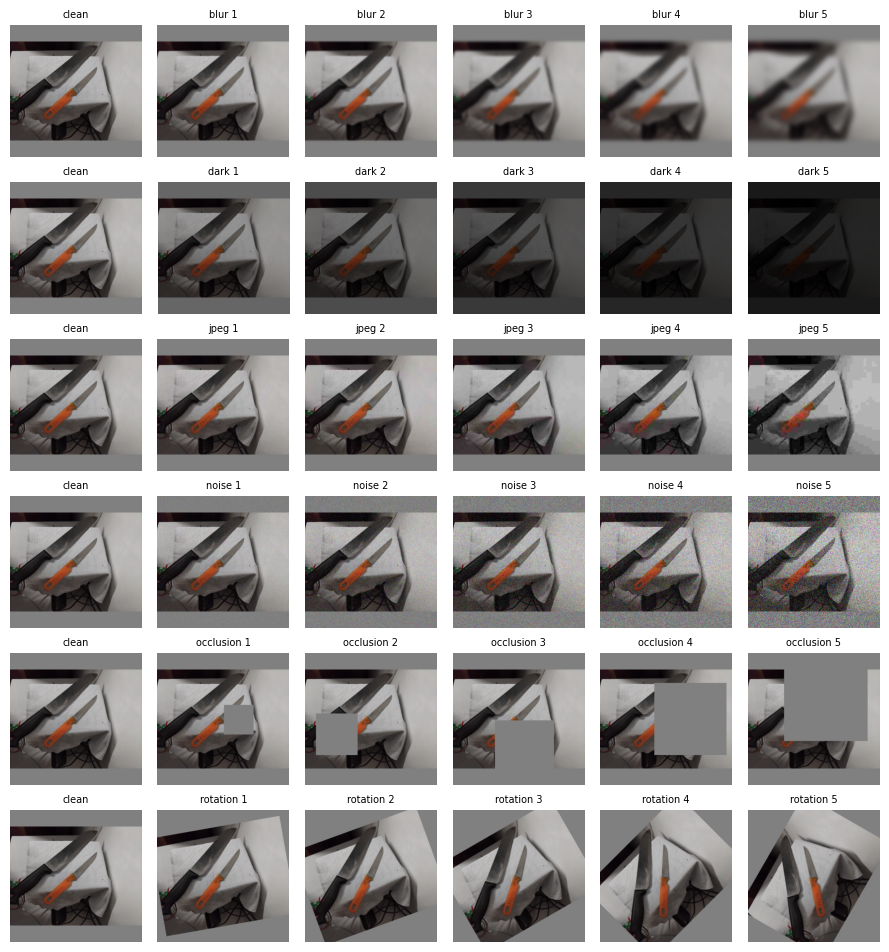

In [3]:
# build all corrupted test sets once (same images for every model and fold)
cfgs = {m: cfg_of(m) for m in MODELS}
assert len({(c["size"], c["res"], c["color"], c["bg"]) for c in cfgs.values()}) == 1, cfgs
cfg0 = next(iter(cfgs.values())); print("recipe F:", cfg0)
assert cfg0["bg"] == "kept", "recipe F keeps the background"

clean = []
for r in tst.itertuples(index=False):
    rgb = np.asarray(Image.open(STAGE0 / r.path).convert("RGB"))
    if cfg0["color"] == "clahe":
        rgb = clahe_rgb(rgb)
    clean.append(geometric(rgb, cfg0, PAD_GRAY))
clean = np.stack(clean)
KIND_ID = {k: i for i, k in enumerate(SEVERITY)}
t0 = time.time(); SETS = {}
for kind, lvl in CONDS:
    if kind == "clean":
        SETS[(kind, lvl)] = clean; continue
    rng = np.random.default_rng(SEED + lvl)            # as in Notebook 3
    SETS[(kind, lvl)] = np.stack([corrupt(im, kind, lvl, rng) for im in clean])
print(f"{len(SETS)} test sets built in {time.time() - t0:.0f} s ({sum(v.nbytes for v in SETS.values()) / 1e9:.1f} GB)")

# example figure: one test image under every corruption
ex = 0
fig, axes = plt.subplots(len(SEVERITY), 6, figsize=(9, 1.6 * len(SEVERITY)))
for i, kind in enumerate(SEVERITY):
    for j in range(6):
        im = SETS[("clean", 0)][ex] if j == 0 else SETS[(kind, j)][ex]
        axes[i, j].imshow(im); axes[i, j].axis("off")
        axes[i, j].set_title("clean" if j == 0 else f"{kind} {j}", fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "example_corruptions.png", dpi=150); plt.show()

In [4]:
@torch.no_grad()
def predict(net, imgs, color, mean, std, bs=64):
    p1, p2 = [], []
    for i in range(0, len(imgs), bs):
        x = to_tensor(imgs[i:i + bs], color, mean, std).to(DEVICE)
        with torch.autocast(device_type="cuda", enabled=(DEVICE == "cuda")):
            a = net(x).float(); b = net(torch.flip(x, dims=[3])).float()
        p1.append(F_.softmax(a, 1).cpu()); p2.append(F_.softmax(b, 1).cpu())
    p1, p2 = torch.cat(p1).numpy(), torch.cat(p2).numpy()
    return p1, (p1 + p2) / 2                      # single view, flip TTA (recipe F)

rows, PROBS = [], {}
for m in MODELS:
    folds = folds_of(m); print(f"{NAME[m]}: folds {folds}")
    for k in folds:
        t0 = time.time()
        net, cfg, mean, std = load_net(m, k)
        for kind, lvl in CONDS:
            p_single, p_tta = predict(net, SETS[(kind, lvl)], cfg["color"], mean, std)
            PROBS[(m, k, kind, lvl)] = p_tta.astype(np.float16)
            for view, p in (("single", p_single), ("tta", p_tta)):
                pr = p.argmax(1)
                rows.append({"model": m, "fold": k, "corruption": kind, "severity": lvl, "view": view,
                             "macro_f1": f1_score(y, pr, average="macro", labels=range(len(CLASSES)), zero_division=0),
                             "accuracy": (pr == y).mean(), "n": len(y)})
        del net; torch.cuda.empty_cache() if DEVICE == "cuda" else None
        d = pd.DataFrame(rows); d = d[(d.model == m) & (d.fold == k) & (d.view == "tta")]
        print(f"  fold {k}: clean {d[d.corruption == 'clean'].macro_f1.iloc[0]:.4f} | "
              f"mean over 30 corruptions {d[d.corruption != 'clean'].macro_f1.mean():.4f} | {time.time() - t0:.0f} s")
    pd.DataFrame(rows).to_csv(OUT / "robustness_rows.csv", index=False)       # saved after every model

rob = pd.DataFrame(rows)
rob.to_csv(OUT / "robustness_rows.csv", index=False)
np.savez_compressed(OUT / "robustness_probs.npz", image_id=tst.image_id.to_numpy(), y=y,
                    **{f"{m}|{k}|{c}|{s}": v for (m, k, c, s), v in PROBS.items()})
t = (rob[rob.view == "tta"].groupby(["model", "corruption", "severity"]).macro_f1
     .agg(["mean", "std"]).round(3).unstack("severity"))
display(t)
with zipfile.ZipFile(WORK / f"robustness_5fold_{PART}.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.iterdir():
        z.write(f, f"{OUT.name}/{f.name}")
print("Done:", WORK / f"robustness_5fold_{PART}.zip")

ConvNeXt-Tiny: folds [0, 1, 2, 3, 4]
  fold 0: clean 0.9927 | mean over 30 corruptions 0.9028 | 166 s
  fold 1: clean 0.9977 | mean over 30 corruptions 0.9304 | 165 s
  fold 2: clean 0.9954 | mean over 30 corruptions 0.9130 | 165 s
  fold 3: clean 0.9977 | mean over 30 corruptions 0.9170 | 165 s
  fold 4: clean 0.9977 | mean over 30 corruptions 0.9272 | 165 s
ViT-S/16: folds [0, 1, 2, 3, 4]
  fold 0: clean 0.9977 | mean over 30 corruptions 0.9608 | 127 s
  fold 1: clean 0.9954 | mean over 30 corruptions 0.9686 | 126 s
  fold 2: clean 1.0000 | mean over 30 corruptions 0.9629 | 127 s
  fold 3: clean 0.9977 | mean over 30 corruptions 0.9635 | 126 s
  fold 4: clean 1.0000 | mean over 30 corruptions 0.9700 | 126 s


mean                                       std                                   
severity                              0      1      2      3      4      5      0      1      2      3      4      5
model                 corruption                                                                                    
convnext_tiny         blur          NaN  0.996  0.983  0.835  0.528  0.266    NaN  0.002  0.008  0.033  0.068  0.078
                      clean       0.996    NaN    NaN    NaN    NaN    NaN  0.002    NaN    NaN    NaN    NaN    NaN
                      dark          NaN  0.997  0.997  0.996  0.989  0.924    NaN  0.002  0.001  0.002  0.010  0.088
                      jpeg          NaN  0.997  0.995  0.992  0.991  0.967    NaN  0.001  0.003  0.003  0.002  0.008
                      noise         NaN  0.996  0.991  0.979  0.948  0.828    NaN  0.001  0.003  0.007  0.013  0.032
                      occlusion     NaN  0.990  0.984  0.914  0.818  0.656    NaN  0.003  0.006  0.016  0.029  0.038
                      rotation      NaN  0.998  0.998  0.998  0.997  0.995    NaN  0.002  0.001  0.001  0.001  0.002
vit_small_patch16_224 blur          NaN  0.998  0.992  0.969  0.903  0.789    NaN  0.002  0.004  0.009  0.014  0.031
                      clean       0.998    NaN    NaN    NaN    NaN    NaN  0.002    NaN    NaN    NaN    NaN    NaN
                      dark          NaN  0.998  0.998  0.998  0.977  0.894    NaN  0.002  0.002  0.002  0.009  0.049
                      jpeg          NaN  0.995  0.995  0.992  0.987  0.967    NaN  0.004  0.004  0.004  0.007  0.008
                      noise         NaN  0.999  0.996  0.989  0.978  0.902    NaN  0.002  0.002  0.006  0.007  0.018
                      occlusion     NaN  0.997  0.990  0.951  0.909  0.816    NaN  0.003  0.004  0.007  0.007  0.011
                      rotation      NaN  0.998  0.997  0.997  0.995  0.990    NaN  0.002  0.003  0.003  0.003  0.007

Done: /kaggle/working/robustness_5fold_B.zip
